In [ ]:
# thousands='.' para importar correctamente la columna de totales

# df = pd.read_csv("../data/nombre.csv", sep=";", thousands=".")


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# 05003 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por tipo hecho
df = pd.read_csv("../data/05003 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por tipo hecho.csv", sep=";", thousands=".")
df

,Comunidades autónomas,Tipología penal,periodo,Total
0,TOTAL NACIONAL,ABUSO SEXUAL,2025,0
1,TOTAL NACIONAL,ABUSO SEXUAL,2024,0
2,TOTAL NACIONAL,ABUSO SEXUAL,2023,0
3,TOTAL NACIONAL,ABUSO SEXUAL,2022,131
4,TOTAL NACIONAL,ABUSO SEXUAL,2021,168
...,...,...,...,...
18145,DESCONOCIDA,TOTAL tipo hecho,2015,0
18146,DESCONOCIDA,TOTAL tipo hecho,2014,0
18147,DESCONOCIDA,TOTAL tipo hecho,2013,0
18148,DESCONOCIDA,TOTAL tipo hecho,2012,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18150 entries, 0 to 18149
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Comunidades autónomas  18150 non-null  str  
 1   Tipología penal        18150 non-null  str  
 2   periodo                18150 non-null  int64
 3   Total                  18150 non-null  int64
dtypes: int64(2), str(2)
memory usage: 567.3 KB


In [4]:
df.columns

Index(['Comunidades autónomas', 'Tipología penal', 'periodo', 'Total'], dtype='str')

In [3]:
df["Comunidades autónomas"].unique()

<StringArray>
[              'TOTAL NACIONAL',                    'ANDALUCÍA',
                       'ARAGÓN',     'ASTURIAS (PRINCIPADO DE)',
              'BALEARS (ILLES)',                     'CANARIAS',
                    'CANTABRIA',              'CASTILLA Y LEÓN',
         'CASTILLA - LA MANCHA',                     'CATALUÑA',
         'COMUNITAT VALENCIANA',                  'EXTREMADURA',
                      'GALICIA',        'MADRID (COMUNIDAD DE)',
           'MURCIA (REGIÓN DE)', 'NAVARRA (COMUNIDAD FORAL DE)',
                   'PAÍS VASCO',                   'RIOJA (LA)',
     'CIUDAD AUTÓNOMA DE CEUTA',   'CIUDAD AUTÓNOMA DE MELILLA',
             'EN EL EXTRANJERO',                  'DESCONOCIDA']
Length: 22, dtype: str

In [6]:
df["Tipología penal"].unique()

<StringArray>
[                                                                                        'ABUSO SEXUAL',
                                                                         'ABUSO SEXUAL CON PENETRACIÓN',
                                             'ACCESO FRAUDULENTO A SERVICIOS DE RADIODIFUSIÓN/TV/OTROS',
                                                                'ACCESO ILEGAL A SISTEMAS INFORMÁTICOS',
                                                                            'ACCESO ILEGAL INFORMÁTICO',
                                                             'ACOSO CONTRA LA LIBERTAD DE LAS PERSONAS',
                                                                         'ACOSO LABORAL O FUNCIONARIAL',
                                                                                         'ACOSO SEXUAL',
                                                                                      'AGRESIÓN SEXUAL',
                                         

In [2]:
df["periodo"].unique()

array([2025, 2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015,
       2014, 2013, 2012, 2011])

In [7]:
df.head()

,Comunidades autónomas,Tipología penal,periodo,Total
0,TOTAL NACIONAL,ABUSO SEXUAL,2025,0
1,TOTAL NACIONAL,ABUSO SEXUAL,2024,0
2,TOTAL NACIONAL,ABUSO SEXUAL,2023,0
3,TOTAL NACIONAL,ABUSO SEXUAL,2022,131
4,TOTAL NACIONAL,ABUSO SEXUAL,2021,168


In [12]:
# Filtra el total nacional y ordena de mayor a menor por la columna Total
df[df["Comunidades autónomas"] != "TOTAL NACIONAL"].sort_values(by='Total', ascending=False).head(10)


,Comunidades autónomas,Tipología penal,periodo,Total
1635,ANDALUCÍA,TOTAL tipo hecho,2025,89124
1636,ANDALUCÍA,TOTAL tipo hecho,2024,81526
1637,ANDALUCÍA,TOTAL tipo hecho,2023,81327
11537,MADRID (COMUNIDAD DE),TOTAL tipo hecho,2023,78881
8237,CATALUÑA,TOTAL tipo hecho,2023,76213
8236,CATALUÑA,TOTAL tipo hecho,2024,76079
11536,MADRID (COMUNIDAD DE),TOTAL tipo hecho,2024,73477
8235,CATALUÑA,TOTAL tipo hecho,2025,73400
11535,MADRID (COMUNIDAD DE),TOTAL tipo hecho,2025,72217
8238,CATALUÑA,TOTAL tipo hecho,2022,63877


In [ ]:
# Filtramos para excluir el total nacional Y el total del grupo penal
df_filtrado = df[
    (df["Comunidades autónomas"] != "TOTAL NACIONAL") & 
    (df["Tipología penal"] != "TOTAL tipo hecho")
]

# Ordenamos de mayor a menor 
df_filtrado.sort_values(by="Total", ascending=False).head(10)


,Comunidades autónomas,Tipología penal,periodo,Total
7832,CATALUÑA,ESTAFA BANCARIA,2023,46605
11162,MADRID (COMUNIDAD DE),"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2023,44144
7831,CATALUÑA,ESTAFA BANCARIA,2024,41828
7833,CATALUÑA,ESTAFA BANCARIA,2022,41153
1260,ANDALUCÍA,"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2025,40959
11161,MADRID (COMUNIDAD DE),"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2024,37698
1261,ANDALUCÍA,"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2024,37430
1262,ANDALUCÍA,"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2023,35310
11163,MADRID (COMUNIDAD DE),"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2022,34578
7835,CATALUÑA,ESTAFA BANCARIA,2020,33242


In [4]:
# condición de filtrado
df_filtrado = df[
    (df["Comunidades autónomas"] != "TOTAL NACIONAL") & 
    (df["Tipología penal"] != "TOTAL tipo hecho")
]

# el índice del valor Total más alto para cada Año
indices_maximos = df_filtrado.groupby("periodo")["Total"].idxmax()

# filas correspondientes a esos índices
df_maximos_por_anio = df_filtrado.loc[indices_maximos]

# resultado ordenado por año
df_maximos_por_anio.sort_values(by="periodo")


,Comunidades autónomas,Tipología penal,periodo,Total
1484,ANDALUCÍA,OTRAS ESTAFAS,2011,2768
1483,ANDALUCÍA,OTRAS ESTAFAS,2012,2888
1482,ANDALUCÍA,OTRAS ESTAFAS,2013,2685
1481,ANDALUCÍA,OTRAS ESTAFAS,2014,3274
7840,CATALUÑA,ESTAFA BANCARIA,2015,11722
7839,CATALUÑA,ESTAFA BANCARIA,2016,13782
7838,CATALUÑA,ESTAFA BANCARIA,2017,20401
7837,CATALUÑA,ESTAFA BANCARIA,2018,27788
7836,CATALUÑA,ESTAFA BANCARIA,2019,30287
7835,CATALUÑA,ESTAFA BANCARIA,2020,33242


In [5]:
df_maximos_por_anio.sort_values(by="periodo", ascending=False)


,Comunidades autónomas,Tipología penal,periodo,Total
1260,ANDALUCÍA,"ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQ...",2025,40959
7831,CATALUÑA,ESTAFA BANCARIA,2024,41828
7832,CATALUÑA,ESTAFA BANCARIA,2023,46605
7833,CATALUÑA,ESTAFA BANCARIA,2022,41153
7834,CATALUÑA,ESTAFA BANCARIA,2021,31252
7835,CATALUÑA,ESTAFA BANCARIA,2020,33242
7836,CATALUÑA,ESTAFA BANCARIA,2019,30287
7837,CATALUÑA,ESTAFA BANCARIA,2018,27788
7838,CATALUÑA,ESTAFA BANCARIA,2017,20401
7839,CATALUÑA,ESTAFA BANCARIA,2016,13782


In [6]:
df["Comunidades autónomas"].unique()

<StringArray>
[              'TOTAL NACIONAL',                    'ANDALUCÍA',
                       'ARAGÓN',     'ASTURIAS (PRINCIPADO DE)',
              'BALEARS (ILLES)',                     'CANARIAS',
                    'CANTABRIA',              'CASTILLA Y LEÓN',
         'CASTILLA - LA MANCHA',                     'CATALUÑA',
         'COMUNITAT VALENCIANA',                  'EXTREMADURA',
                      'GALICIA',        'MADRID (COMUNIDAD DE)',
           'MURCIA (REGIÓN DE)', 'NAVARRA (COMUNIDAD FORAL DE)',
                   'PAÍS VASCO',                   'RIOJA (LA)',
     'CIUDAD AUTÓNOMA DE CEUTA',   'CIUDAD AUTÓNOMA DE MELILLA',
             'EN EL EXTRANJERO',                  'DESCONOCIDA']
Length: 22, dtype: str

In [7]:
# Tipología penal

# condición de filtrado
df_dataset3 = df[
    (df["Comunidades autónomas"] == "TOTAL NACIONAL") & 
    (df["Tipología penal"] != "TOTAL tipo hecho")
]

df_dataset3 




,Comunidades autónomas,Tipología penal,periodo,Total
0,TOTAL NACIONAL,ABUSO SEXUAL,2025,0
1,TOTAL NACIONAL,ABUSO SEXUAL,2024,0
2,TOTAL NACIONAL,ABUSO SEXUAL,2023,0
3,TOTAL NACIONAL,ABUSO SEXUAL,2022,131
4,TOTAL NACIONAL,ABUSO SEXUAL,2021,168
...,...,...,...,...
805,TOTAL NACIONAL,USURPACIÓN DE FUNCIONES PÚBLICAS,2015,0
806,TOTAL NACIONAL,USURPACIÓN DE FUNCIONES PÚBLICAS,2014,0
807,TOTAL NACIONAL,USURPACIÓN DE FUNCIONES PÚBLICAS,2013,0
808,TOTAL NACIONAL,USURPACIÓN DE FUNCIONES PÚBLICAS,2012,0


In [ ]:
# Guardado en csv del Dataset 3 
df_dataset3.sort_values(by=["periodo", "Total"], ascending=[False, False]).to_csv(
    "../data/dataset3_tipologia_delitos.csv", index=False, sep=";"
)

In [8]:
# Agrupar por tipología acumulada
ranking_tipos = df_dataset3.groupby("Tipología penal")["Total"].sum().sort_values(ascending=False)

ranking_tipos


Tipología penal
ESTAFAS CON TARJETAS DE CRÉDITO, DÉBITO Y CHEQUES DE VIAJE                                              1177949
OTRAS ESTAFAS                                                                                           1060872
ESTAFA BANCARIA                                                                                          400067
AMENAZAS                                                                                                 157472
ESTAFAS INFORMÁTICAS                                                                                     148887
USURPACIÓN DE ESTADO CIVIL                                                                               105783
DESCUBRIMIENTO/REVELACIÓN DE SECRETOS                                                                     32992
COACCIONES                                                                                                23202
ACCESO ILEGAL INFORMÁTICO                                                               

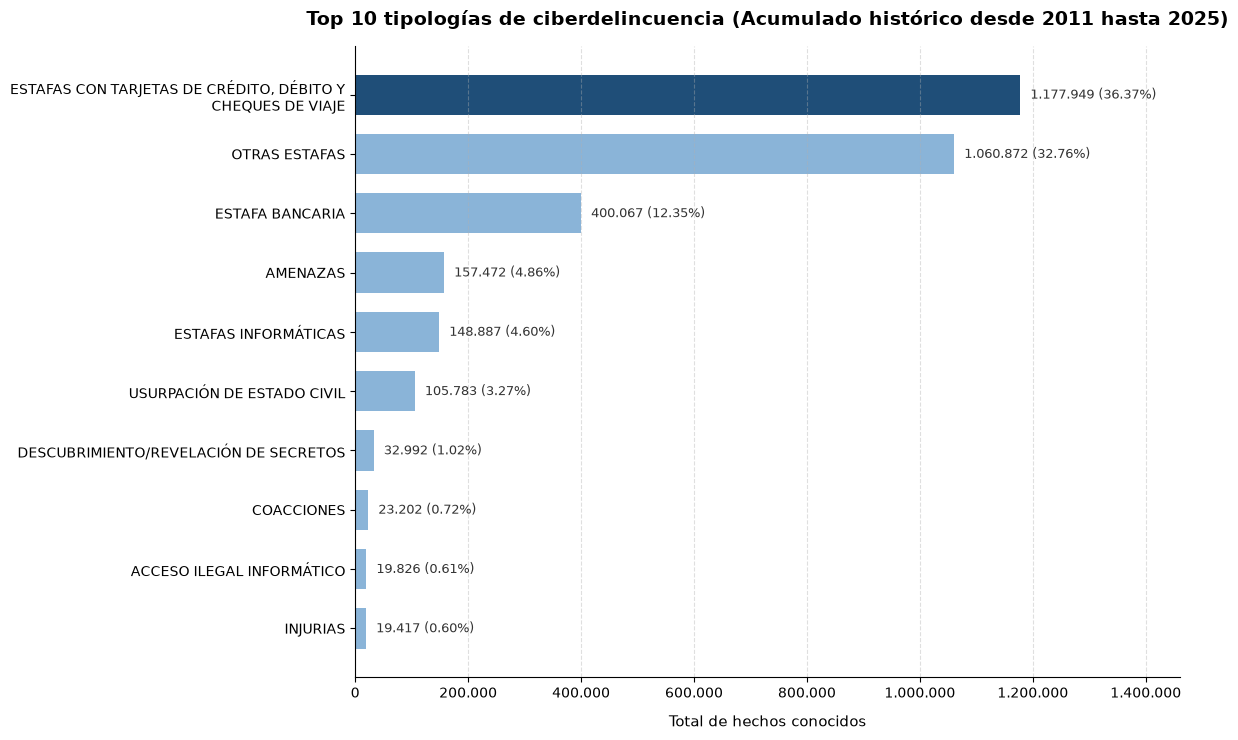

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import textwrap

total_global = ranking_tipos.sum()

top10_plot = ranking_tipos.head(10).sort_values(ascending=True)
porcentajes = (top10_plot / total_global) * 100

# Acortar o dividir etiquetas muy largas en 2 líneas (máx. 42 caracteres por línea) 
etiquetas_limpias = [textwrap.fill(str(nombre), width=42) for nombre in top10_plot.index]

# Creación de la figura
fig, ax = plt.subplots(figsize=(12, 7.5))

# Destacar la tipología líder en un azul más oscuro
colores = ["#8ab4d8"] * (len(top10_plot) - 1) + ["#1f4e78"]
bars = ax.barh(etiquetas_limpias, top10_plot.values, color=colores, height=0.68)

# Títulos y ejes
ax.set_title("Top 10 tipologías de ciberdelincuencia (Acumulado histórico desde 2011 hasta 2025)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Total de hechos conocidos", fontsize=11, labelpad=10)

# Formatear el eje X con separador de miles (punto)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", ".")))

# Limpiar bordes superiores y derechos
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)

# Añadir etiquetas con el número exacto y el porcentaje sobre el total nacional
margen = top10_plot.max() * 0.015
for bar, pct in zip(bars, porcentajes):
    valor = int(bar.get_width())
    valor_fmt = f"{valor:,}".replace(",", ".")
    ax.text(
        bar.get_width() + margen,
        bar.get_y() + bar.get_height() / 2,
        f"{valor_fmt} ({pct:.2f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#333333"
    )

# Ampliar margen derecho para que la etiqueta de la barra superior no se corte
ax.set_xlim(0, top10_plot.max() * 1.24)

plt.tight_layout()
plt.show()


In [ ]:

# 05003 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por tipo hecho
